# Problema 1 - Regressão Linear Múltipla: Previsão de Produção de Energia (CCPP)

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/FredGregorio/Disciplina-sistemas-inteligentes-2026.2/blob/main/Primeira%20Unidade/Projetos/01-regressao-linear-ccpp/src/problema1.ipynb)

## 1. Importando as bibliotecas e carregando os dados

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

plt.rcParams['figure.figsize'] = (8, 4)

In [2]:
# Se o arquivo existir na pasta do projeto, estamos rodando no PC.
# Se não existir (ex.: Google Colab), baixamos o mesmo arquivo do GitHub.
if os.path.exists("../data/ccpp.csv"):
    caminho_dados = "../data/ccpp.csv"
    pasta_resultados = "../resultados"
else:
    caminho_dados = "https://raw.githubusercontent.com/FredGregorio/Disciplina-sistemas-inteligentes-2026.2/main/Primeira%20Unidade/Projetos/01-regressao-linear-ccpp/data/ccpp.csv"
    pasta_resultados = "resultados"

os.makedirs(pasta_resultados, exist_ok=True)   # pasta onde salvamos os gráficos

df = pd.read_csv(caminho_dados)
df.head()

,AT,V,AP,RH,PE
0,14.96,41.76,1024.07,73.17,463.26
1,25.18,62.96,1020.04,59.08,444.37
2,5.11,39.40,1012.16,92.14,488.56
3,20.86,57.32,1010.24,76.64,446.48
4,10.82,37.50,1009.23,96.62,473.90


In [3]:
print(f"Quantidade de amostras = {df.shape[0]}")
print(f"Quantidade de colunas  = {df.shape[1]}")
print()
print("Valores ausentes por coluna:")
print(df.isna().sum())

Quantidade de amostras = 9568
Quantidade de colunas  = 5

Valores ausentes por coluna:
AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64


In [4]:
df.describe()

,AT,V,AP,RH,PE
count,9568.000000,9568.000000,9568.000000,9568.000000,9568.000000
mean,19.651231,54.305804,1013.259078,73.308978,454.365009
std,7.452473,12.707893,5.938784,14.600269,17.066995
min,1.810000,25.360000,992.890000,25.560000,420.260000
25%,13.510000,41.740000,1009.100000,63.327500,439.750000
50%,20.345000,52.080000,1012.940000,74.975000,451.550000
75%,25.720000,66.540000,1017.260000,84.830000,468.430000
max,37.110000,81.560000,1033.300000,100.160000,495.760000


## 2. Tarefa 1 - Correlação entre as variáveis independentes e a variável alvo (PE)

In [5]:
corr = df.corr()

# Só a correlação de cada variável com PE, ordenada pela força (valor absoluto)
corr_com_PE = corr["PE"].drop("PE")
print(corr_com_PE.sort_values(key=abs, ascending=False))

AT   -0.948128
V    -0.869780
AP    0.518429
RH    0.389794
Name: PE, dtype: float64


## 3. Tarefa 2 - Correlação entre as variáveis independentes

In [6]:
corr_entre_si = df[["AT", "V", "AP", "RH"]].corr()
print(corr_entre_si.round(3))

       AT      V     AP     RH
AT  1.000  0.844 -0.508 -0.543
V   0.844  1.000 -0.414 -0.312
AP -0.508 -0.414  1.000  0.100
RH -0.543 -0.312  0.100  1.000


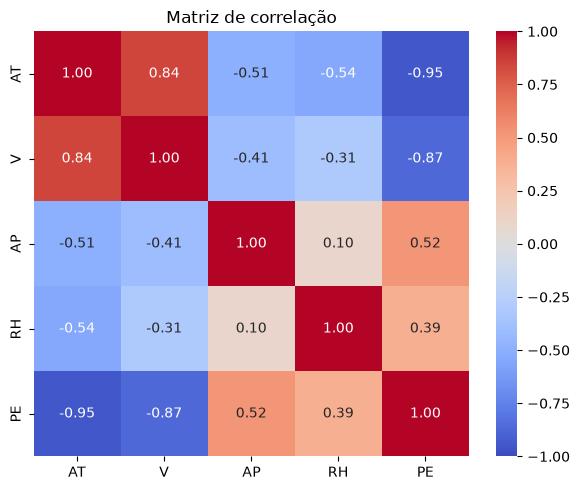

In [7]:
plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de correlação")
plt.tight_layout()
plt.savefig(f"{pasta_resultados}/correlacao.png", dpi=150)
plt.show()

## 4. Tarefa 3 - Construindo o modelo de regressão linear múltipla

In [8]:
X = df[["AT", "V", "AP", "RH"]]
y = df["PE"]

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Amostras de treinamento = {X_train.shape[0]}")
print(f"Amostras de teste       = {X_test.shape[0]}")

Amostras de treinamento = 7654
Amostras de teste       = 1914


In [10]:
scaler = StandardScaler()

X_train_sc = scaler.fit_transform(X_train)   # aprende média/desvio no treino e aplica
X_test_sc  = scaler.transform(X_test)        # só aplica (usa média/desvio do treino)

In [11]:
model = LinearRegression()
model.fit(X_train_sc, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4,)","[-14.76, -2.95, 0.37, -2.31]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,454.4
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(4)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](4,)","[136.66, 83.33, 64.89, 28.05]"


In [12]:
coef = pd.Series(model.coef_, index=X.columns)
print("Intercepto (theta0):", round(model.intercept_, 4))
print()
print("Coeficientes (theta1...):")
print(coef.round(4))

Intercepto (theta0): 454.431

Coeficientes (theta1...):
AT   -14.7639
V     -2.9496
AP     0.3698
RH    -2.3122
dtype: float64


## 5. Tarefa 4 - Avaliação do modelo

In [13]:
y_pred_train = model.predict(X_train_sc)
y_pred_test  = model.predict(X_test_sc)

def metricas(y_real, y_prev):
    r2   = r2_score(y_real, y_prev)
    rmse = np.sqrt(mean_squared_error(y_real, y_prev))
    mae  = mean_absolute_error(y_real, y_prev)
    return r2, rmse, mae

r2_tr, rmse_tr, mae_tr = metricas(y_train, y_pred_train)
r2_te, rmse_te, mae_te = metricas(y_test,  y_pred_test)

print(f"TREINO -> R2 = {r2_tr:.4f} | RMSE = {rmse_tr:.4f} MW | MAE = {mae_tr:.4f} MW")
print(f"TESTE  -> R2 = {r2_te:.4f} | RMSE = {rmse_te:.4f} MW | MAE = {mae_te:.4f} MW")
print()
print(f"Para comparar: o desvio padrão de PE é {y.std():.2f} MW")

TREINO -> R2 = 0.9283 | RMSE = 4.5709 MW | MAE = 3.6300 MW
TESTE  -> R2 = 0.9301 | RMSE = 4.5026 MW | MAE = 3.5959 MW

Para comparar: o desvio padrão de PE é 17.07 MW


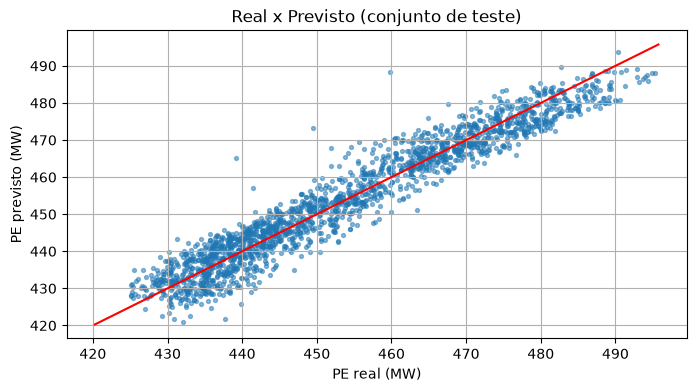

In [14]:
plt.scatter(y_test, y_pred_test, s=8, alpha=0.5)
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r')
plt.xlabel("PE real (MW)")
plt.ylabel("PE previsto (MW)")
plt.title("Real x Previsto (conjunto de teste)")
plt.grid()
plt.savefig(f"{pasta_resultados}/real_vs_previsto.png", dpi=150)
plt.show()

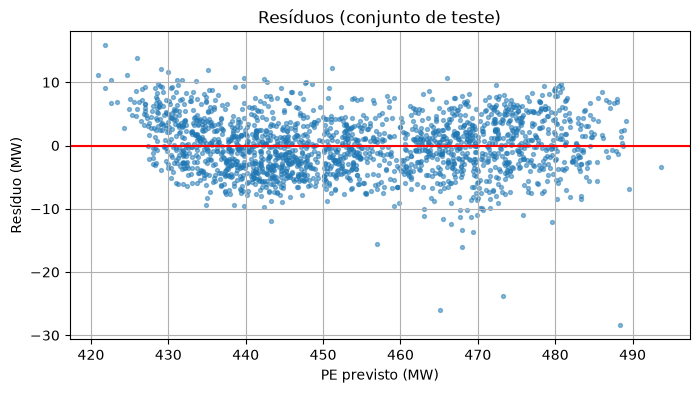

In [15]:
residuos = y_test - y_pred_test

plt.scatter(y_pred_test, residuos, s=8, alpha=0.5)
plt.axhline(0, color='r')
plt.xlabel("PE previsto (MW)")
plt.ylabel("Resíduo (MW)")
plt.title("Resíduos (conjunto de teste)")
plt.grid()
plt.savefig(f"{pasta_resultados}/residuos.png", dpi=150)
plt.show()